# 1. Librerías y funciones

In [1]:
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
pd.options.mode.chained_assignment = None 
import os
import sys
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.signal.signaltools
import statsmodels.formula.api as smf
from sklearn import tree
from sklearn import metrics
from sklearn.tree import DecisionTreeRegressor,DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor,RandomForestClassifier
from sklearn.tree import plot_tree
from sklearn.model_selection import train_test_split
from datetime import date
from datetime import datetime
from dateutil.relativedelta import relativedelta
from matplotlib.backends.backend_pdf import PdfPages
from scipy.stats import ks_2samp
import lightgbm as lgb
import pycaret

In [2]:
print(f"pycaret version: {pycaret.__version__}")

pycaret version: 3.3.2


In [3]:
sys.path.append('C:/Users/s2660778/The Bank of Nova Scotia/Gonzales Cornejo, Kevin Fausto - 023. Estimador_Ingresos_Cliente/Librerias')

In [4]:
import sbp_modelos as sbp

# 2. Importando data

In [5]:
# Importando tabla
df_TRAIN = pd.read_parquet("C://Users//s2660778//The Bank of Nova Scotia//Gonzales Cornejo, Kevin Fausto - 023. Estimador_Ingresos_Cliente//Bases//Variables_candidatas_AutoML_Sprint_4_VF2.parquet", engine='pyarrow')
df_TRAIN.shape

(509198, 22)

In [6]:
df_TRAIN.head(5)

,INGRESO_CAP_V2,ID_REGISTRO,MAX_GARHIP_120M,MAX_HIPOTECARIO_2010,MAX_CONSUMO_TOP4_60M,MAX_MAX_LINCRE_TOP4_24M,MED_PAY_24M,AVG_CONSUMO_TOTAL_60M,AVG_RED_CONSUMO_TOTAL_24M,AVG_RED_CONSUMO_TOTAL_3M,...,GHIGHESTBAL_NORM48,MAX_GARVEH_2010,MAX_COMPRAS_TC_48M,AVG_SALDO_TOTAL_TOP4_12M,MAX_CONSUMO_24M,MED_RCC_S_TOT_U12M_6CONS,MAX_VEHICULAR_60M,MONTO_TRANSACCIONES_12M,MAX_IMPORTEPEN_12M,GBAL1PCTAVGBAL1TO3
0,5200.140,704403,NaN,NaN,21025.65,6000.00,NaN,12072.924000,1213.103846,1307.77,...,16338.478979,NaN,5802.70,3909.1375,35275.81,NaN,0.0,NaN,NaN,106.535776
1,1737.745,370731,NaN,NaN,0.00,NaN,NaN,488.681250,126.600000,126.60,...,599.600000,NaN,599.60,0.0000,599.60,NaN,0.0,NaN,NaN,102.153429
4,2716.055,960411,NaN,NaN,2000.00,NaN,NaN,515.462308,NaN,NaN,...,307.692200,NaN,0.00,0.0000,0.00,NaN,0.0,NaN,NaN,NaN
9,2223.710,367534,398241.0,186503.77,50203.53,10000.01,NaN,8095.975333,2552.255000,2000.66,...,49000.000000,42088.15,9873.69,3207.9375,7976.83,NaN,0.0,NaN,NaN,NaN
10,7012.585,918182,NaN,NaN,20596.62,22100.82,NaN,7549.547500,2778.679000,1938.80,...,15732.169415,NaN,20596.62,9093.4475,20596.62,NaN,0.0,NaN,NaN,112.736423


In [7]:
df_TRAIN.shape

(509198, 22)

---

# 3. Tratamiento de datos

In [8]:
df_AUTO_ML = df_TRAIN.drop(columns=['ID_REGISTRO'])

In [9]:
df_AUTO_ML.head(3)

,INGRESO_CAP_V2,MAX_GARHIP_120M,MAX_HIPOTECARIO_2010,MAX_CONSUMO_TOP4_60M,MAX_MAX_LINCRE_TOP4_24M,MED_PAY_24M,AVG_CONSUMO_TOTAL_60M,AVG_RED_CONSUMO_TOTAL_24M,AVG_RED_CONSUMO_TOTAL_3M,MED_RED_CONSUMO_NREV_24M,...,GHIGHESTBAL_NORM48,MAX_GARVEH_2010,MAX_COMPRAS_TC_48M,AVG_SALDO_TOTAL_TOP4_12M,MAX_CONSUMO_24M,MED_RCC_S_TOT_U12M_6CONS,MAX_VEHICULAR_60M,MONTO_TRANSACCIONES_12M,MAX_IMPORTEPEN_12M,GBAL1PCTAVGBAL1TO3
0,5200.140,NaN,NaN,21025.65,6000.0,NaN,12072.924000,1213.103846,1307.77,909.03,...,16338.478979,NaN,5802.7,3909.1375,35275.81,NaN,0.0,NaN,NaN,106.535776
1,1737.745,NaN,NaN,0.00,NaN,NaN,488.681250,126.600000,126.60,NaN,...,599.600000,NaN,599.6,0.0000,599.60,NaN,0.0,NaN,NaN,102.153429
4,2716.055,NaN,NaN,2000.00,NaN,NaN,515.462308,NaN,NaN,NaN,...,307.692200,NaN,0.0,0.0000,0.00,NaN,0.0,NaN,NaN,NaN


In [10]:
data=df_AUTO_ML
target='INGRESO_CAP_V2'
data.shape

(509198, 21)

In [12]:
#   from sklearn.preprocessing import LabelEncoder
#   le = LabelEncoder()
#   data['CARRERA'] = le.fit_transform(data['CARRERA'])

In [13]:
data.dtypes

INGRESO_CAP_V2               float64
MAX_GARHIP_120M              float64
MAX_HIPOTECARIO_2010         float64
MAX_CONSUMO_TOP4_60M         float64
MAX_MAX_LINCRE_TOP4_24M      float64
MED_PAY_24M                  float64
AVG_CONSUMO_TOTAL_60M        float64
AVG_RED_CONSUMO_TOTAL_24M    float64
AVG_RED_CONSUMO_TOTAL_3M     float64
MED_RED_CONSUMO_NREV_24M     float64
MED_PASIVOS_IC_MIN3_6M       float64
GHIGHESTBAL_NORM48           float64
MAX_GARVEH_2010              float64
MAX_COMPRAS_TC_48M           float64
AVG_SALDO_TOTAL_TOP4_12M     float64
MAX_CONSUMO_24M              float64
MED_RCC_S_TOT_U12M_6CONS     float64
MAX_VEHICULAR_60M            float64
MONTO_TRANSACCIONES_12M      float64
MAX_IMPORTEPEN_12M           float64
GBAL1PCTAVGBAL1TO3           float64
dtype: object

Text(0, 0.5, 'Densidad')

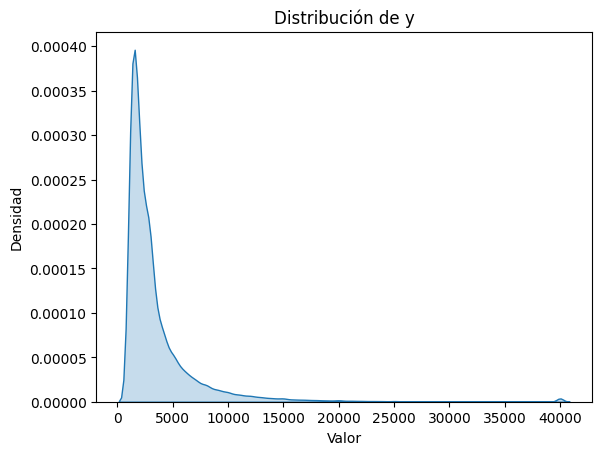

In [14]:
sns.kdeplot(data['INGRESO_CAP_V2'], label='y', shade=True)
plt.title('Distribución de y')
plt.xlabel('Valor')
plt.ylabel('Densidad')

In [15]:
data.shape

(509198, 21)

# 4. AutoML

In [16]:
#from pycaret.classification import *
from pycaret.regression import *
s = setup(data = data, target = target, session_id = 666)

,Description,Value
0,Session id,666
1,Target,INGRESO_CAP_V2
2,Target type,Regression
3,Original data shape,"(509198, 21)"
4,Transformed data shape,"(509198, 21)"
5,Transformed train set shape,"(356438, 21)"
6,Transformed test set shape,"(152760, 21)"
7,Numeric features,20
8,Rows with missing values,99.7%
9,Preprocess,True


In [17]:
best_model = compare_models(exclude=['gbr','rf','ada','et'])

,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE,TT (Sec)
catboost,CatBoost Regressor,1265.5596,6210250.6876,2491.4077,0.6195,0.4373,0.3888,37.2380
lightgbm,Light Gradient Boosting Machine,1280.0431,6257724.4784,2500.8866,0.6166,0.4430,0.3963,2.9640
xgboost,Extreme Gradient Boosting,1283.9792,6470209.3000,2542.9330,0.6036,0.4404,0.3910,2.4290
knn,K Neighbors Regressor,1416.1744,7772350.1500,2787.5632,0.5236,0.4871,0.4214,16.7600
lr,Linear Regression,1564.8771,8816986.7500,2966.6994,0.4600,0.5454,0.5414,3.0540
lasso,Lasso Regression,1564.8769,8816987.8500,2966.6995,0.4600,0.5454,0.5414,20.7740
ridge,Ridge Regression,1564.8773,8816986.3500,2966.6993,0.4600,0.5454,0.5414,0.4260
en,Elastic Net,1564.8768,8816987.6500,2966.6995,0.4600,0.5454,0.5414,20.4720
llar,Lasso Least Angle Regression,1564.8769,8816989.4500,2966.6998,0.4600,0.5454,0.5414,0.3640
br,Bayesian Ridge,1564.7705,8817978.8500,2966.8537,0.4599,0.5454,0.5415,0.6660
